In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# ============================================================
# PATH
# ============================================================
RESULT_DIR = Path(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/calc_files/MI/MT_read_fraction/conditional_mi_MT_fraction_all_genes_results"
)


# ============================================================
# DATASET LABELS
# ============================================================

name_map = {
    "treutlein": "HBO1",
    "weinreb": "MHSPC",
    "junker": "ZFL",

    "knoblich_day16_1": "HBO2_16_1",
    "knoblich_day16_2": "HBO2_16_2",
    "knoblich_day42_1": "HBO2_42_1",
    "knoblich_day42_2": "HBO2_42_2",

    "you1": "HBO3_1",
    "you2": "HBO3_2",
    "you3": "HBO3_3",
    "you4": "HBO3_4",
}


dataset_order = [
    "HBO1",
    "MHSPC",
    "ZFL",
    "HBO2_16_1",
    "HBO2_16_2",
    "HBO2_42_1",
    "HBO2_42_2",
    "HBO3_1",
    "HBO3_2",
    "HBO3_3",
    "HBO3_4",
]


# ============================================================
# FIND RESULT FILES
# ============================================================

result_files = sorted(
    RESULT_DIR.glob(
        "conditional_MI_MT_fraction_all_genes_*_q5_no_permutations.csv"
    )
)

print(f"Found {len(result_files)} files:\n")

for file in result_files:
    print(file.name)


# ============================================================
# LOAD
# ============================================================

dfs = []

for file in result_files:

    df = pd.read_csv(file)

    dfs.append(df)


if len(dfs) == 0:
    raise FileNotFoundError(
        f"No files found in {RESULT_DIR.resolve()}"
    )


cmi_all = pd.concat(
    dfs,
    ignore_index=True,
)


# ============================================================
# NICE DATASET LABELS
# ============================================================

cmi_all["dataset_label"] = (
    cmi_all["dataset"].map(name_map)
)

cmi_all["dataset_label"] = pd.Categorical(
    cmi_all["dataset_label"],
    categories=dataset_order,
    ordered=True,
)


# ============================================================
# BASIC OVERVIEW
# ============================================================

print("\nCombined dataframe shape:")
print(cmi_all.shape)

print("\nDatasets loaded:")

display(
    cmi_all[
        ["dataset", "dataset_label"]
    ]
    .drop_duplicates()
    .sort_values("dataset_label")
)

print("\nColumns:")

print(
    cmi_all.columns.tolist()
)

Found 11 files:

conditional_MI_MT_fraction_all_genes_junker_q5_no_permutations.csv
conditional_MI_MT_fraction_all_genes_knoblich_day16_1_q5_no_permutations.csv
conditional_MI_MT_fraction_all_genes_knoblich_day16_2_q5_no_permutations.csv
conditional_MI_MT_fraction_all_genes_knoblich_day42_1_q5_no_permutations.csv
conditional_MI_MT_fraction_all_genes_knoblich_day42_2_q5_no_permutations.csv
conditional_MI_MT_fraction_all_genes_treutlein_q5_no_permutations.csv
conditional_MI_MT_fraction_all_genes_weinreb_q5_no_permutations.csv
conditional_MI_MT_fraction_all_genes_you1_q5_no_permutations.csv
conditional_MI_MT_fraction_all_genes_you2_q5_no_permutations.csv
conditional_MI_MT_fraction_all_genes_you3_q5_no_permutations.csv
conditional_MI_MT_fraction_all_genes_you4_q5_no_permutations.csv

Combined dataframe shape:
(282313, 26)

Datasets loaded:


,dataset,dataset_label
137342,treutlein,HBO1
158198,weinreb,MHSPC
0,junker,ZFL
21062,knoblich_day16_1,HBO2_16_1
50377,knoblich_day16_2,HBO2_16_2
79295,knoblich_day42_1,HBO2_42_1
108294,knoblich_day42_2,HBO2_42_2
180834,you1,HBO3_1
206183,you2,HBO3_2
233037,you3,HBO3_3



Columns:
['gene', 'is_mt_gene', 'requested_quantile_bins', 'actual_quantile_bins', 'n_cells_used', 'n_lineages_used', 'quantile_edges', 'unconditional_mi', 'conditional_mi_mt_fraction_LOO', 'delta_cmi_minus_mi', 'H_lineage', 'H_mt_fraction_bin', 'H_lineage_given_mt_fraction', 'mean_mt_fraction_LOO', 'median_mt_fraction_LOO', 'error', 'dataset', 'min_cells_per_lineage', 'n_cells_before_lineage_filter', 'n_cells_after_lineage_filter', 'n_lineages_before_filter', 'n_lineages_after_lineage_filter', 'mt_fraction_definition', 'expression_discretization', 'permutations', 'dataset_label']


In [3]:
# ============================================================
# CELL 2 — REMOVE FAILED ROWS
# ============================================================

failed_rows = cmi_all[
    cmi_all["error"].fillna("").str.len() > 0
].copy()

print(f"Failed rows: {len(failed_rows)}")

if len(failed_rows) > 0:
    display(
        failed_rows[
            [
                "dataset_label",
                "gene",
                "error",
            ]
        ]
    )


# ------------------------------------------------------------
# Remove failed calculations
# ------------------------------------------------------------

cmi_all_clean = cmi_all[
    cmi_all["error"].fillna("").str.len() == 0
].copy()


print("\nRows before filtering:", len(cmi_all))
print("Rows after filtering: ", len(cmi_all_clean))
print("Rows removed:         ", len(cmi_all) - len(cmi_all_clean))

Failed rows: 14


,dataset_label,gene,error
79281,HBO2_16_2,TBCE,ValueError: operands could not be broadcast to...
79282,HBO2_16_2,TBCE,ValueError: operands could not be broadcast to...
79283,HBO2_16_2,LINC01238,ValueError: operands could not be broadcast to...
79284,HBO2_16_2,LINC01238,ValueError: operands could not be broadcast to...
79285,HBO2_16_2,CYB561D2,ValueError: operands could not be broadcast to...
79286,HBO2_16_2,CYB561D2,ValueError: operands could not be broadcast to...
79287,HBO2_16_2,MATR3,ValueError: operands could not be broadcast to...
79288,HBO2_16_2,MATR3,ValueError: operands could not be broadcast to...
79289,HBO2_16_2,HSPA14,ValueError: operands could not be broadcast to...
79290,HBO2_16_2,HSPA14,ValueError: operands could not be broadcast to...



Rows before filtering: 282313
Rows after filtering:  282299
Rows removed:          14


In [4]:
# ============================================================
# CELL 3 — SANITY CHECKS
# ============================================================


# ------------------------------------------------------------
# 1. Number of genes and MT genes per dataset
# ------------------------------------------------------------

gene_summary = (
    cmi_all_clean.groupby(
        "dataset_label",
        observed=True,
    )
    .agg(
        n_genes=("gene", "nunique"),
        n_MT_genes=("is_mt_gene", "sum"),
    )
    .reset_index()
)

print("Genes per dataset:")
display(gene_summary)


# ------------------------------------------------------------
# 2. Missing values in important columns
# ------------------------------------------------------------

key_columns = [
    "unconditional_mi",
    "conditional_mi_mt_fraction_LOO",
    "actual_quantile_bins",
    "n_cells_used",
    "n_lineages_used",
    "H_lineage",
    "H_mt_fraction_bin",
]

print("\nMissing values:")

display(
    cmi_all_clean[key_columns]
    .isna()
    .sum()
    .to_frame("n_missing")
)


# ------------------------------------------------------------
# 3. Requested vs actual number of bins
# ------------------------------------------------------------

print("\nRequested vs actual number of MT-fraction bins:")

display(
    cmi_all_clean.groupby(
        [
            "requested_quantile_bins",
            "actual_quantile_bins",
        ],
        observed=True,
    )
    .size()
    .rename("n_genes")
    .reset_index()
)


bin_mismatch = cmi_all_clean[
    cmi_all_clean["requested_quantile_bins"]
    != cmi_all_clean["actual_quantile_bins"]
]

print(
    f"\nRows with actual bins != requested bins: "
    f"{len(bin_mismatch)}"
)


# ------------------------------------------------------------
# 4. Same cells / lineages used for every gene?
# ------------------------------------------------------------

sample_check = (
    cmi_all_clean.groupby(
        "dataset_label",
        observed=True,
    )
    .agg(
        n_cells_min=("n_cells_used", "min"),
        n_cells_max=("n_cells_used", "max"),
        n_lineages_min=("n_lineages_used", "min"),
        n_lineages_max=("n_lineages_used", "max"),
    )
    .reset_index()
)

print("\nCells and lineages used:")
display(sample_check)


# ------------------------------------------------------------
# 5. Negative MI / CMI values
# ------------------------------------------------------------

print("\nNegative values:")

print(
    "Negative MI:",
    (cmi_all_clean["unconditional_mi"] < -1e-10).sum()
)

print(
    "Negative CMI:",
    (
        cmi_all_clean["conditional_mi_mt_fraction_LOO"]
        < -1e-10
    ).sum()
)


# ------------------------------------------------------------
# 6. MI / CMI ranges
# ------------------------------------------------------------

range_summary = (
    cmi_all_clean.groupby(
        "dataset_label",
        observed=True,
    )
    .agg(
        MI_min=("unconditional_mi", "min"),
        MI_max=("unconditional_mi", "max"),
        CMI_min=("conditional_mi_mt_fraction_LOO", "min"),
        CMI_max=("conditional_mi_mt_fraction_LOO", "max"),
        median_delta=("delta_cmi_minus_mi", "median"),
    )
    .reset_index()
)

print("\nMI / CMI ranges:")
display(range_summary.round(4))

Genes per dataset:


,dataset_label,n_genes,n_MT_genes
0,HBO1,20856,13
1,MHSPC,22636,13
2,ZFL,21062,13
3,HBO2_16_1,29315,13
4,HBO2_16_2,28904,13
5,HBO2_42_1,28999,13
6,HBO2_42_2,29048,13
7,HBO3_1,25349,13
8,HBO3_2,26854,13
9,HBO3_3,25990,13



Missing values:


,n_missing
unconditional_mi,0
conditional_mi_mt_fraction_LOO,0
actual_quantile_bins,0
n_cells_used,0
n_lineages_used,0
H_lineage,0
H_mt_fraction_bin,0



Requested vs actual number of MT-fraction bins:


,requested_quantile_bins,actual_quantile_bins,n_genes
0,5,5.0,282299



Rows with actual bins != requested bins: 0

Cells and lineages used:


,dataset_label,n_cells_min,n_cells_max,n_lineages_min,n_lineages_max
0,HBO1,16506.0,16506.0,3905.0,3905.0
1,MHSPC,49302.0,49302.0,5864.0,5864.0
2,ZFL,6191.0,6191.0,210.0,210.0
3,HBO2_16_1,5695.0,5695.0,149.0,149.0
4,HBO2_16_2,8730.0,8730.0,188.0,188.0
5,HBO2_42_1,9533.0,9533.0,157.0,157.0
6,HBO2_42_2,8109.0,8109.0,160.0,160.0
7,HBO3_1,18650.0,18650.0,17075.0,17075.0
8,HBO3_2,42640.0,42640.0,33308.0,33308.0
9,HBO3_3,23883.0,23883.0,15792.0,15792.0



Negative values:
Negative MI: 0
Negative CMI: 0

MI / CMI ranges:


,dataset_label,MI_min,MI_max,CMI_min,CMI_max,median_delta
0,HBO1,0.0005,2.4240,0.0004,2.8511,0.0407
1,MHSPC,0.0004,2.2407,0.0003,3.4901,0.0059
2,ZFL,0.0009,0.8919,0.0010,1.8345,0.0105
3,HBO2_16_1,0.0008,0.5693,0.0008,0.9718,0.0477
4,HBO2_16_2,0.0005,0.3302,0.0005,0.7710,0.0356
5,HBO2_42_1,0.0002,0.1966,0.0002,0.4333,0.0154
6,HBO2_42_2,0.0003,0.4092,0.0002,0.8218,0.0258
7,HBO3_1,0.0013,4.6611,0.0012,4.7203,-0.0003
8,HBO3_2,0.0005,4.4749,0.0005,4.7543,0.0101
9,HBO3_3,0.0008,4.1756,0.0007,4.6340,0.0242


In [5]:
# ============================================================
# CELL 4 — CHECK NEW UNCONDITIONAL MI AGAINST ORIGINAL MI
# ============================================================

MI_DIR = Path(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/"
    "calc_files/MI/"
    "mi_analysis_results_MI_label_entropy_all_genes_parallel_with_BH"
)


# ------------------------------------------------------------
# Find original 10,000-permutation MI files
# ------------------------------------------------------------

original_mi_dfs = []

for dataset in name_map.keys():

    matches = sorted(
        MI_DIR.glob(
            f"MI_label_entropy_{dataset}_10000_permutations_with_BH.csv"
        )
    )

    if len(matches) != 1:
        print(
            f"WARNING: {dataset}: found {len(matches)} matching files"
        )
        continue

    df = pd.read_csv(matches[0])

    df["dataset"] = dataset

    original_mi_dfs.append(
        df[
            [
                "dataset",
                "gene",
                "true_mi",
            ]
        ].copy()
    )


original_mi = pd.concat(
    original_mi_dfs,
    ignore_index=True,
)

print(
    "Original MI rows loaded:",
    f"{len(original_mi):,}"
)


# ------------------------------------------------------------
# Identify duplicated gene symbols
# ------------------------------------------------------------

duplicate_original = (
    original_mi.groupby(
        ["dataset", "gene"]
    )
    .size()
    .reset_index(name="n")
)

duplicate_original = duplicate_original[
    duplicate_original["n"] > 1
]

print(
    "Duplicated dataset/gene combinations in original MI:",
    len(duplicate_original)
)


# ------------------------------------------------------------
# For this sanity check, compare only uniquely represented genes
# ------------------------------------------------------------

original_unique = original_mi[
    ~original_mi.duplicated(
        ["dataset", "gene"],
        keep=False,
    )
].copy()

new_unique = cmi_all_clean[
    ~cmi_all_clean.duplicated(
        ["dataset", "gene"],
        keep=False,
    )
][
    [
        "dataset",
        "gene",
        "unconditional_mi",
    ]
].copy()


mi_check = new_unique.merge(
    original_unique,
    on=["dataset", "gene"],
    how="inner",
)


# ------------------------------------------------------------
# Difference
# ------------------------------------------------------------

mi_check["difference"] = (
    mi_check["unconditional_mi"]
    - mi_check["true_mi"]
)

mi_check["abs_difference"] = (
    mi_check["difference"].abs()
)


# ------------------------------------------------------------
# Dataset-level summary
# ------------------------------------------------------------

mi_check_summary = (
    mi_check.groupby("dataset")
    .agg(
        n_genes_compared=("gene", "size"),
        median_abs_difference=(
            "abs_difference",
            "median",
        ),
        mean_abs_difference=(
            "abs_difference",
            "mean",
        ),
        max_abs_difference=(
            "abs_difference",
            "max",
        ),
    )
    .reset_index()
)

mi_check_summary["dataset_label"] = (
    mi_check_summary["dataset"].map(name_map)
)

mi_check_summary["dataset_label"] = pd.Categorical(
    mi_check_summary["dataset_label"],
    categories=dataset_order,
    ordered=True,
)

mi_check_summary = (
    mi_check_summary
    .sort_values("dataset_label")
)


display(
    mi_check_summary[
        [
            "dataset_label",
            "n_genes_compared",
            "median_abs_difference",
            "mean_abs_difference",
            "max_abs_difference",
        ]
    ]
)


print(
    "\nOverall maximum absolute difference:",
    mi_check["abs_difference"].max()
)

Original MI rows loaded: 282,313
Duplicated dataset/gene combinations in original MI: 7


,dataset_label,n_genes_compared,median_abs_difference,mean_abs_difference,max_abs_difference
5,HBO1,20856,1.551537e-14,3.120704e-14,2.489120e-13
6,MHSPC,22636,4.120142e-14,7.984581e-13,1.223732e-11
0,ZFL,21062,5.294376e-15,2.865875e-14,5.925260e-13
1,HBO2_16_1,29315,5.002943e-15,9.641036e-15,8.532064e-14
2,HBO2_16_2,28904,9.096890e-15,2.037074e-14,2.536860e-13
3,HBO2_42_1,28999,2.303713e-15,3.892556e-15,3.477774e-14
4,HBO2_42_2,29048,6.002143e-15,4.227948e-14,2.864375e-13
7,HBO3_1,25349,5.384582e-15,8.619100e-09,1.789253e-04
8,HBO3_2,26854,1.382505e-13,5.455994e-10,9.881536e-06
9,HBO3_3,25990,1.119521e-13,4.165170e-13,2.913669e-12



Overall maximum absolute difference: 0.00017892530110907856


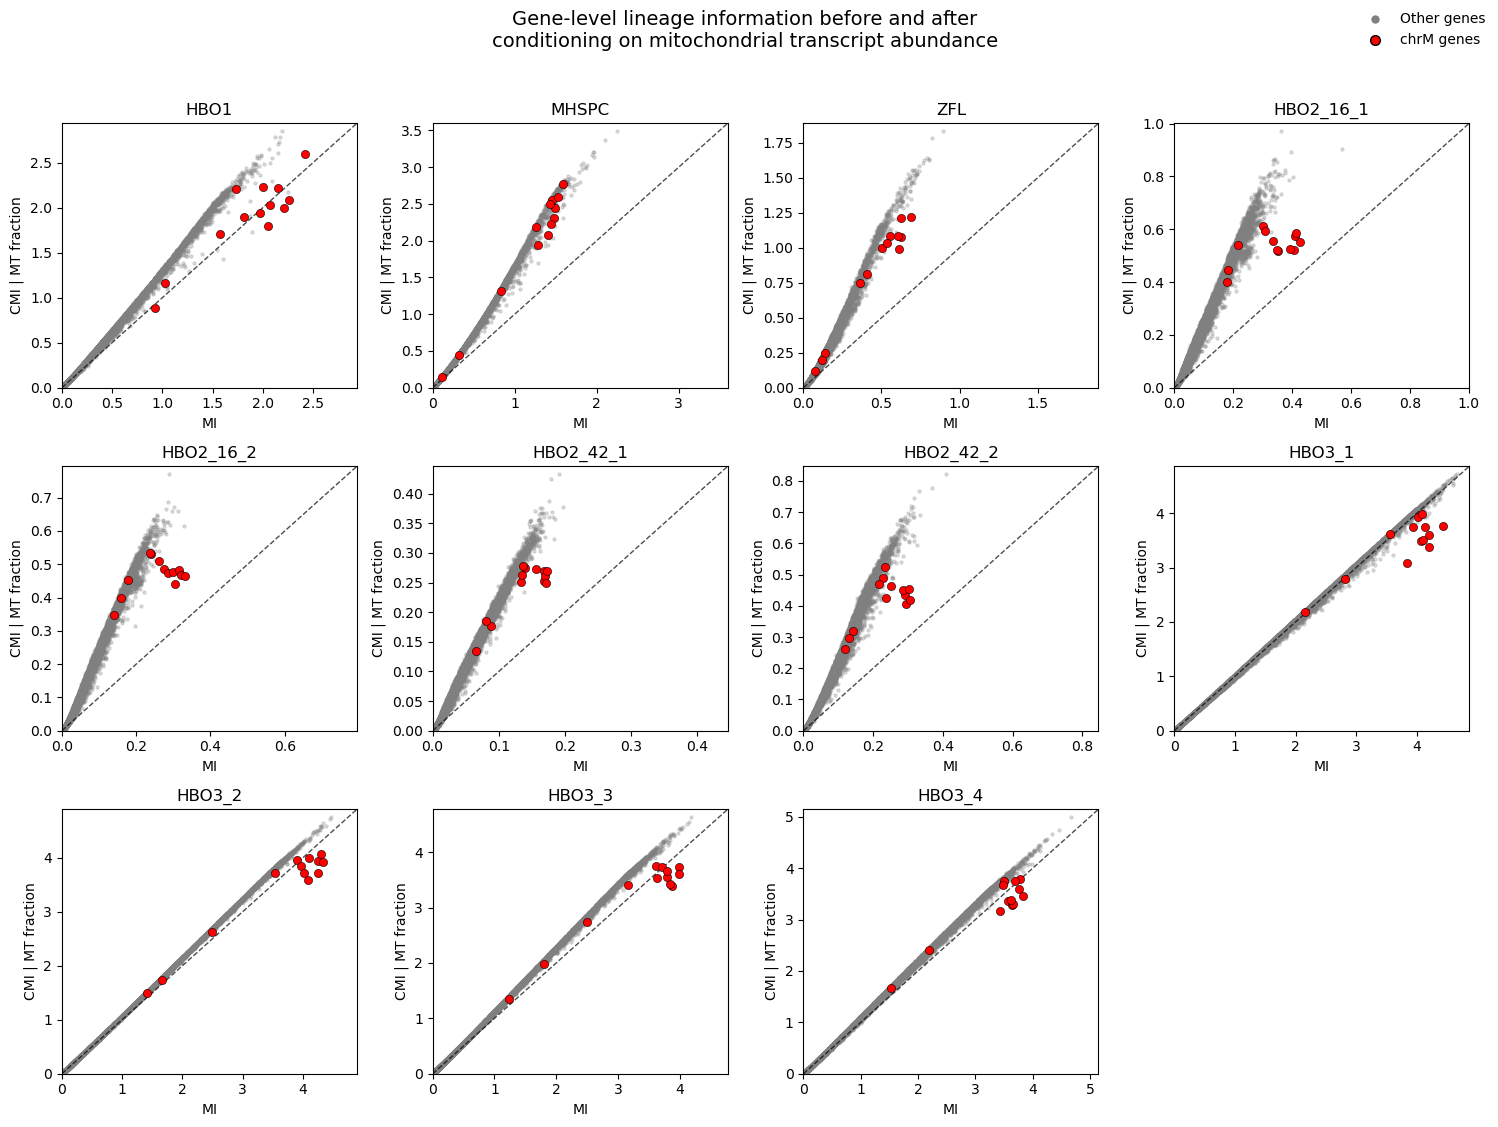

In [8]:
# ============================================================
# CELL 5 — ALL-GENE MI vs CMI SCATTER PLOTS
# ============================================================

plot_df = cmi_all_clean.copy()

plot_df["dataset_label"] = pd.Categorical(
    plot_df["dataset_label"],
    categories=dataset_order,
    ordered=True,
)

plot_df = plot_df.sort_values("dataset_label")


# ------------------------------------------------------------
# Figure layout
# ------------------------------------------------------------

ncols = 4
nrows = int(np.ceil(len(dataset_order) / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(15, 11),
)

axes = axes.flatten()


# ------------------------------------------------------------
# Plot each dataset
# ------------------------------------------------------------

for ax, dataset in zip(axes, dataset_order):

    sub = plot_df[
        plot_df["dataset_label"] == dataset
    ].copy()

    non_mt = sub[
        ~sub["is_mt_gene"].astype(bool)
    ]

    mt = sub[
        sub["is_mt_gene"].astype(bool)
    ]


    # --------------------------------------------------------
    # All other genes
    # --------------------------------------------------------

    ax.scatter(
        non_mt["unconditional_mi"],
        non_mt["conditional_mi_mt_fraction_LOO"],
        s=5,
        alpha=0.25,
        color="grey",
        rasterized=True,
    )


    # --------------------------------------------------------
    # Mitochondrial genes
    # --------------------------------------------------------

    ax.scatter(
        mt["unconditional_mi"],
        mt["conditional_mi_mt_fraction_LOO"],
        s=35,
        color="red",
        edgecolor="black",
        linewidth=0.4,
        zorder=5,
    )


    # --------------------------------------------------------
    # Same limits for x and y within this dataset
    # --------------------------------------------------------

    max_val = max(
        sub["unconditional_mi"].max(),
        sub["conditional_mi_mt_fraction_LOO"].max(),
    )

    max_val *= 1.03

    ax.set_xlim(0, max_val)
    ax.set_ylim(0, max_val)


    # --------------------------------------------------------
    # y = x reference
    # --------------------------------------------------------

    ax.plot(
        [0, max_val],
        [0, max_val],
        linestyle="--",
        color="black",
        linewidth=1,
        alpha=0.7,
    )


    # --------------------------------------------------------
    # Labels
    # --------------------------------------------------------

    ax.set_title(str(dataset))

    ax.set_xlabel("MI")
    ax.set_ylabel("CMI | MT fraction")


# ------------------------------------------------------------
# Remove unused axes
# ------------------------------------------------------------

for ax in axes[len(dataset_order):]:
    ax.axis("off")


# ------------------------------------------------------------
# Shared legend
# ------------------------------------------------------------

from matplotlib.lines import Line2D

legend_elements = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        markerfacecolor="grey",
        markeredgecolor="none",
        markersize=6,
        label="Other genes",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        markerfacecolor="red",
        markeredgecolor="black",
        markersize=7,
        label="chrM genes",
    ),
]

fig.legend(
    handles=legend_elements,
    loc="upper right",
    frameon=False,
)


fig.suptitle(
    "Gene-level lineage information before and after\n"
    "conditioning on mitochondrial transcript abundance",
    fontsize=14,
    y=1.02,
)

plt.tight_layout()

plt.savefig(
f"scatter_MT_fraction.pdf",
bbox_inches="tight"
)

plt.show()